# Installing Net2Brain

<img src="workshops/data/Net2Brain_Logo.png" width="25%" />

In [1]:
#!pip install -U git+https://github.com/cvai-roig-lab/Net2Brain

# Step 3: Evaluation

In this tutorial notebook, we'll showcase how to leverage the evaluation capabilities of Net2Brain and visualize the resulting data. You can choose from three evaluation metrics:

1. "RSA"
2. "Weighted RSA"
3. "Searchlight"

Each module generates a pandas DataFrame, which can be seamlessly integrated with the toolbox's built-in plotting functionality.

### Representational Similiratiy Analysis (RSA) Evaluation

First load the ROIs

In [3]:
#paths_bonner = DatasetBonnerPNAS2017.load_dataset()
#stimuli_path = paths_bonner["stimuli_path"]
#roi_path = paths_bonner["roi_path"]

from net2brain.utils.download_datasets import DatasetAlgonauts_NSD_Shared
from pprint import pprint
paths_NSD_shared  = DatasetAlgonauts_NSD_Shared.load_dataset()
import os
import numpy as np

stimuli_path = paths_NSD_shared["images"]



In [6]:
#testing shapes
"""
import os
import numpy as np

#brain_path = os.path.join(paths_NSD_shared["root"], "brain_data")  
#brain_path = os.path.join(paths_NSD_shared["root"], "combined_roi_rdms")  # combined lh and rh 
brain_path = r"C:\Users\louai\Net2Brain\notebooks\brain_rdms_final"

file = os.listdir(brain_path)[0]
data = np.load(os.path.join(brain_path, file))

print("File:", file)
print("Keys:", data.files)

# inspect first subject
arr = data[data.files[0]]

print("Shape (one subject):", arr.shape)
print("Min:", arr.min(), "Max:", arr.max())

File: RDM_arr_0.npz
Keys: ['rdm', 'stimuli_name', 'layer_name', 'meta']
Shape (one subject): (0,)


ValueError: zero-size array to reduction operation minimum which has no identity

RSA format expects: (subjects, images, images). if one subject: (1,img,img)

results explaination:
ROI: brain region 
Layer:  
Model:  
R2: how well the model explains brain activity. 0->0.1  
%R2: performance relative to noise ceiling. 45% = model explains half of what is explainable  
R2_array_  
Sig: p-value. < 0.05 → significant   
SEM: error   
LNC: Noise ceilings: lower bound  
UNC: upper bound  

In [4]:
from net2brain.evaluations.rsa import RSA

model_rdms = r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\INFONCE_RDM_nsd_mean" 

brain_rdms = r"C:\Users\louai\Net2Brain\notebooks\Algonauts23_shared_Net2Brain\combined_brain_data_rdms" #combined
#brain_rdms = r"C:\Users\louai\Net2Brain\notebooks\Algonauts23_shared_Net2Brain\brain_data" #non combined
#print(brain_rdms)

# Start RSA
evaluation = RSA(model_rdms, brain_rdms, model_name="INFONCE", squared=True)

# Evaluation - Returns a pandas dataframe
dataframe1 = evaluation.evaluate() 

# Show results
display(dataframe1)

#save results as csv
dataframe1.to_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\infonce_rsa_results_combined_mean.csv", index=False)
#dataframe1.to_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\ibot_rsa_results.csv", index=False)



,ROI,Layer,Model,R2,%R2,R2_array,Significance,SEM,LNC,UNC
0,(0) EBA_combined_RDMs,(0) RDM_layer_1.npz,INFONCE,0.000854,0.201882,"[0.0009240070385605866, 0.0008537960955520808,...",0.000026,0.000088,0.423015,0.535542
1,(0) EBA_combined_RDMs,(1) RDM_layer_2.npz,INFONCE,0.000862,0.203814,"[0.0009520006642996869, 0.0008548171483149951,...",0.000023,0.000087,0.423015,0.535542
2,(0) EBA_combined_RDMs,(2) RDM_layer_3.npz,INFONCE,0.000886,0.209339,"[0.000983674244781205, 0.0008816070168615502, ...",0.000023,0.000090,0.423015,0.535542
3,(0) EBA_combined_RDMs,(3) RDM_layer_4.npz,INFONCE,0.000906,0.214175,"[0.0010059814943519053, 0.0009038440476850648,...",0.000023,0.000091,0.423015,0.535542
4,(0) EBA_combined_RDMs,(4) RDM_layer_5.npz,INFONCE,0.000927,0.219043,"[0.001035002086068643, 0.0009278687121289634, ...",0.000021,0.000093,0.423015,0.535542
...,...,...,...,...,...,...,...,...,...,...
175,(14) VWFA-1_combined_RDMs,(7) RDM_layer_8.npz,INFONCE,0.000864,0.386205,"[0.0013666536368708868, 0.0009929872109823833,...",0.000357,0.000134,0.223829,0.368962
176,(14) VWFA-1_combined_RDMs,(8) RDM_layer_9.npz,INFONCE,0.000883,0.394545,"[0.0014145967869413332, 0.0010057192370252093,...",0.000347,0.000137,0.223829,0.368962
177,(14) VWFA-1_combined_RDMs,(9) RDM_layer_10.npz,INFONCE,0.000862,0.385086,"[0.0013809474147837872, 0.0009784578996078653,...",0.000332,0.000132,0.223829,0.368962
178,(14) VWFA-1_combined_RDMs,(10) RDM_layer_11.npz,INFONCE,0.000843,0.376685,"[0.0013821305949124015, 0.0009377020604832504,...",0.000319,0.000129,0.223829,0.368962


Optional RSA class arguments to consider:
- Argument `layer_skips` to skip certain layers during 
evaluation. This can be
useful when you have a large number of layers extracted and want to test only a subset of them.
- By default the evaluation returns the squared correlations. If you don't want to square the 
correlations, you
should set `squared=False`. This is different from later changing the metric in plotting, as 
correlations are
subject-averaged by then, and also negative correlations cannot be recovered.
- If your neural data is temporal (EEG/MEG), you can specify whether to average across timepoints
 with `timepoint_agg`. By default this is set to True, meaning that the neural RDMs are averaged 
 across timepoints before RSA. If you want to perform RSA at each timepoint separately, set this to False.
- If your video models contain timepoints (e.g. video models features extracted in a 
time-resolved manner and converted to time-resolved RDMs as shown in previous notebooks), you 
should specify this by setting `model_timepoints=True`. By default this is set to False.

# Preparing dataframes and best layers

In [16]:
#get dataframes from csv files
import pandas as pd
# before combining l+r:
#dataframe_jepa_last_layer = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\jepa_rsa_results.csv")
#dataframe_jepa = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\jepa_rsa_results_3.csv")
#dataframe_dino = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\dino_rsa_results.csv")
#dataframe_mae = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\mae_rsa_results.csv")
#dataframe_clip = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\clip_rsa_results.csv")


#after combining l+r
dataframe_jepa_combined = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\jepa_rsa_results_combined_last_layer.csv")
dataframe_jepa_combined_all = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\jepa_rsa_results_combined_all_layers.csv")
dataframe_dino_combined = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\dino_rsa_results_combined.csv")
dataframe_mae_combined = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\mae_rsa_results_combined.csv")
dataframe_ibot_combined = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\ibot_rsa_results_combined.csv")
dataframe_vljepa_combined_cls = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\vljepa_rsa_results_combined_cls.csv")
dataframe_infonce_combined_cls = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\infonce_rsa_results_combined_cls.csv")
dataframe_vljepa_combined_mean = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\vljepa_rsa_results_combined_mean.csv")
dataframe_infonce_combined_mean = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\infonce_rsa_results_combined_mean.csv")

C:\Users\louai\AppData\Local\Temp\ipykernel_14076\152582845.py:17: DtypeWarning: Columns (0,1,5) have mixed types. Specify dtype option on import or set low_memory=False.
  dataframe_vljepa_combined_cls = pd.read_csv(r"C:\Users\louai\Net2Brain\notebooks\0_RSA results\combined\vljepa_rsa_results_combined_cls.csv")


In [38]:
print(dataframe_mae_combined.columns)

Index(['ROI', 'Layer', 'Model', 'R2', '%R2', 'R2_array', 'Significance', 'SEM',
       'LNC', 'UNC'],
      dtype='object')


In [40]:
import numpy as np

arr = np.fromstring(
    row["R2_array"].strip("[]"),
    sep=" "
)

print(type(arr))
print(arr.shape)
print(arr)

<class 'numpy.ndarray'>
(8,)
[0.00107853 0.00100234 0.00105978 0.000587   0.00134388 0.00073613
 0.00135665 0.00097125]


If you want the first row, use: best_jepa.iloc[0]

If you want the layer of the first row: best_jepa.iloc[0]["Layer"]

or specifically for EBA: best_jepa.loc["(0) EBA_combined_RDMs", "Layer"]

In [22]:


# best layer for every roi for 1 model 
best_mae = (
    dataframe_mae_combined
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)

best_jepa = (
    dataframe_jepa_combined_all
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)

best_dino = (
    dataframe_dino_combined
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)
best_ibot = (
    dataframe_ibot_combined
    .sort_values("R2", ascending=False)
    .groupby("ROI")
    .first()
)
#print(best_jepa)


In [12]:
# best performing layer
print(dataframe_mae_combined.sort_values("R2", ascending=False))

<bound method NDFrame.head of                         ROI                  Layer Model        R2       %R2  \
165   (6) PPA_combined_RDMs  (15) RDM_layer_15.npz   MAE  0.016772  6.986728   
164   (6) PPA_combined_RDMs  (14) RDM_layer_14.npz   MAE  0.016362  6.816065   
166   (6) PPA_combined_RDMs  (16) RDM_layer_16.npz   MAE  0.016104  6.708372   
163   (6) PPA_combined_RDMs  (13) RDM_layer_13.npz   MAE  0.015037  6.264077   
168   (6) PPA_combined_RDMs  (18) RDM_layer_18.npz   MAE  0.014673  6.112261   
..                      ...                    ...   ...       ...       ...   
302  (12) V3d_combined_RDMs    (2) RDM_layer_2.npz   MAE  0.000471  0.409785   
125  (5) OWFA_combined_RDMs    (0) RDM_layer_0.npz   MAE  0.000445  0.563916   
301  (12) V3d_combined_RDMs    (1) RDM_layer_1.npz   MAE  0.000365  0.317272   
250  (10) V2d_combined_RDMs    (0) RDM_layer_0.npz   MAE  0.000276  0.205242   
300  (12) V3d_combined_RDMs    (0) RDM_layer_0.npz   MAE  0.000209  0.181598   

         

## Visualizing RSA Evaluation Results

The integrated plotting functionality of the toolbox allows you to easily visualize evaluation results. To achieve this, initialize the class with a list of DataFrames obtained from the evaluation. Make sure that each DataFrame:

1. Contains the same ROIs, signifying that each test was performed on the same brain RDMs.
2. Has a distinct model name, which can be set manually or through the "model_name" parameter during evaluation (as mentioned earlier).

Here's an example of how to plot the data using a single DataFrame:

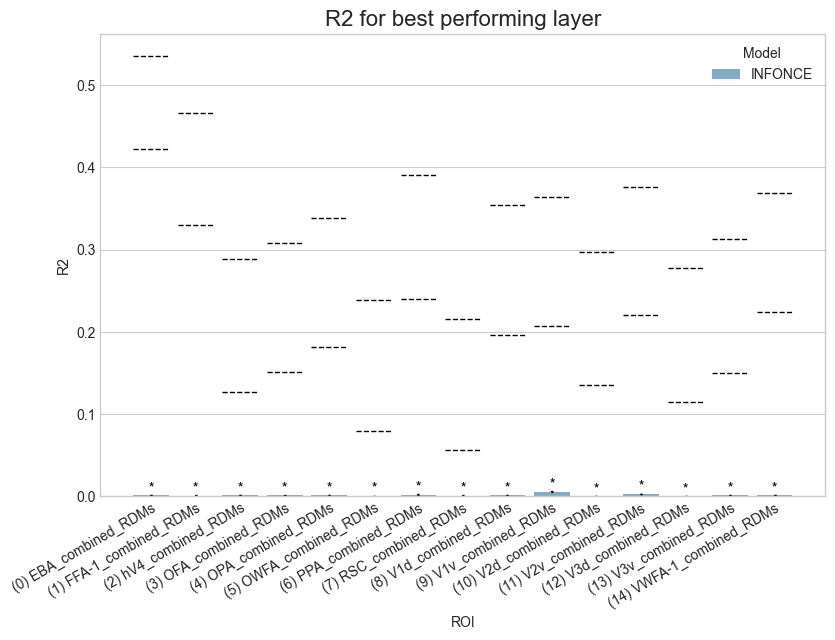

In [5]:

from net2brain.evaluations.plotting import Plotting

plotter = Plotting([dataframe1])
results_dataframe = plotter.plot()

You can choose between `metric="R2"` (default) or `metric="R"`

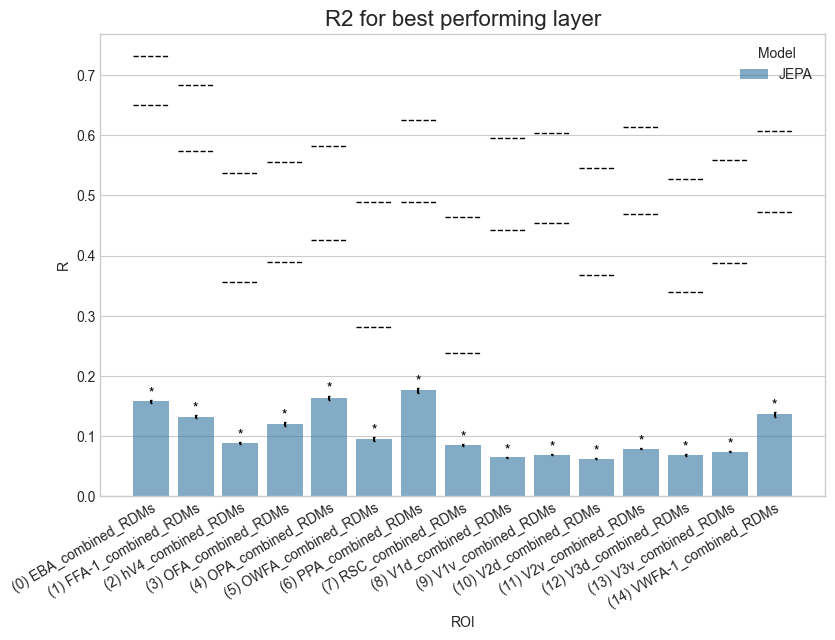

In [8]:
results_dataframe = plotter.plot(metric="R2")

You can also choose between plotting the best layers or `plot_all_layers()`.

In [ ]:
results_dataframe = plotter.plot_all_layers(metric="R2")

## Visualizing RSA Evaluation Results - Multiple models

As previously mentioned, you can also plot multiple models in a single plot. To do this, simply include additional DataFrames in the list:

        Plotting([dataframe1, dataframe2, dataframe3])



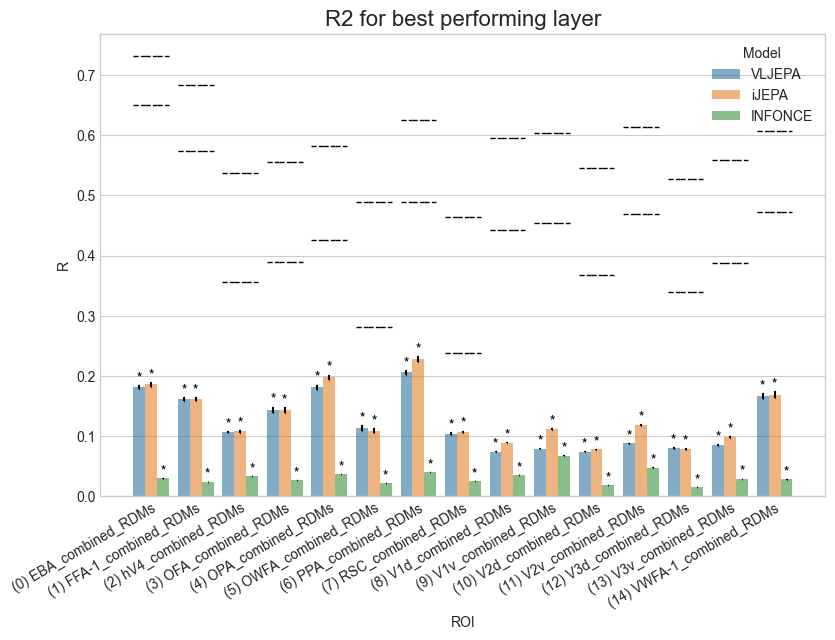

IndexError: list index out of range

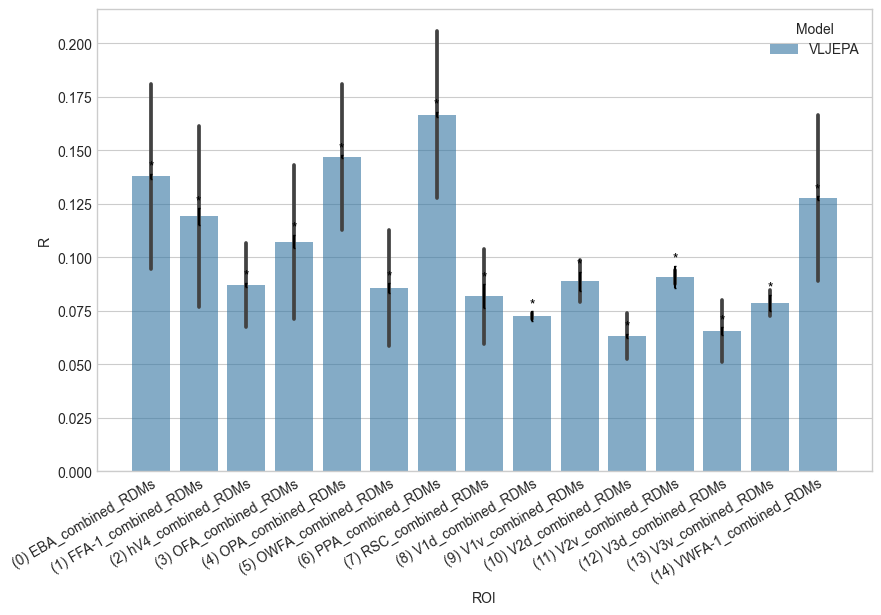

In [13]:
from net2brain.evaluations.plotting import Plotting
plotter = Plotting([  dataframe_vljepa_combined_cls, dataframe_jepa_combined_all, dataframe_infonce_combined_cls])
results_dataframe = plotter.plot(metric = 'R')



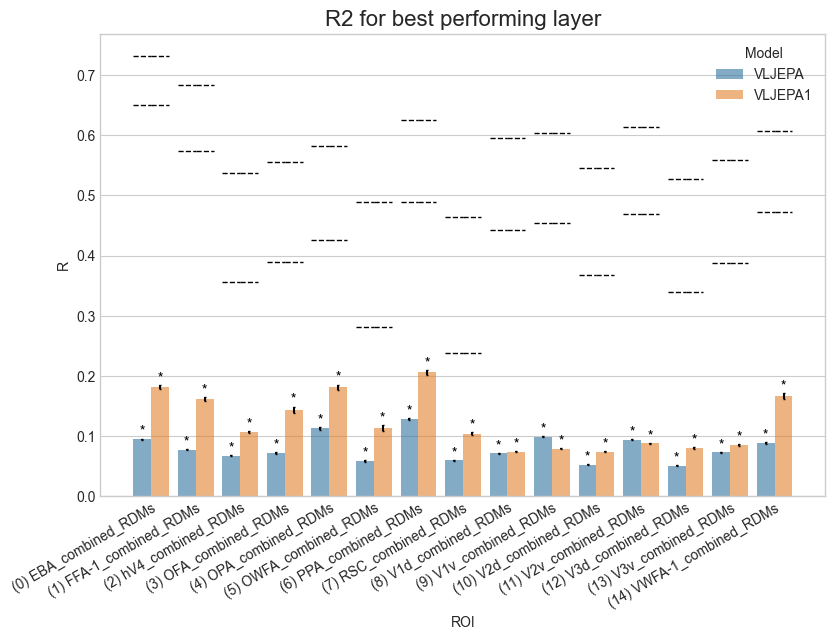

In [17]:
plotter = Plotting([  dataframe_vljepa_combined_mean, dataframe_vljepa_combined_cls])
results_dataframe = plotter.plot(metric = 'R')

## Visualizing RSA Evaluation Results - Multiple models with significance


Furthermore, you might be interested in determining whether one model is significantly better than another, and not merely due to random variation. In this case, you can utilize the `compare_model` functionality provided by the toolbox. Use the following syntax:

        ttest, sig_pairs = eval_1.compare_model(eval_2)

If you wish to display the significance as well, use the parameter pairs=[].

In [6]:
# calc. RSA for first model
model_rdms = r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\MAE_RDM_nsd" 

brain_rdms = r"C:\Users\louai\Net2Brain\notebooks\Algonauts23_shared_Net2Brain\combined_brain_data_rdms" #combined
#brain_rdms = r"C:\Users\louai\Net2Brain\notebooks\Algonauts23_shared_Net2Brain\brain_data" #non combined

evaluation_1 = RSA(model_rdms, brain_rdms, model_name="MAE", squared=True)

# calc. RSA for second model
model_rdms = r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\JEPA_RDM_nsd" 

brain_rdms = r"C:\Users\louai\Net2Brain\notebooks\Algonauts23_shared_Net2Brain\combined_brain_data_rdms" #combined
#brain_rdms = r"C:\Users\louai\Net2Brain\notebooks\Algonauts23_shared_Net2Brain\brain_data" #non combined

evaluation_2 = RSA(model_rdms, brain_rdms, model_name="JEPA", squared=True)

# Comparing statistical significance
ttest, sig_pairs = evaluation_1.compare_model(evaluation_2)
print(sig_pairs)

# Plotting with significance
plotter = Plotting([dataframe_jepa_combined,dataframe_mae_combined])
results_dataframe = plotter.plot(pairs=sig_pairs)

AttributeError: 'RSA' object has no attribute 'distance_metric'

In [25]:
from scipy import stats
import numpy as np

mae_row = best_mae.loc["(0) EBA_combined_RDMs"]
jepa_row = best_jepa.loc["(0) EBA_combined_RDMs"]
# get the R2 values and put them in lists
mae_arr = np.fromstring(
    mae_row["R2_array"].strip("[]"),
    sep=" "
)

jepa_arr = np.fromstring(
    jepa_row["R2_array"].strip("[]"),
    sep=" "
)
# perform the test
t_stat, p_value = stats.ttest_rel(jepa_arr, mae_arr)

print("t =", t_stat)
print("p =", p_value)
print("MAE mean =", mae_arr.mean())
print("iJEPA mean =", jepa_arr.mean())

t = 8.85032620096635
p = 4.756699452281654e-05
MAE mean = 0.009439122500000001
iJEPA mean = 0.034460988750000004


### WRSA Evaluation
In addition to the standard RSA, Net2Brain also supports weighted RSA (WRSA) as an evaluation metric. WRSA allows for the incorporation of weights into the analysis, providing an alternative approach to evaluating model performance and examining the relationship between neural representations and computational models.

In [ ]:
from net2brain.evaluations.weighted_rsa import WRSA

# Start RSA
evaluation = WRSA(model_rdms, brain_rdms, save_path="./", model_name="ResNet50", ridge_weight=0)

# Evaluation - Returns a pandas dataframe
dataframe1 = evaluation.evaluate() 

display(dataframe1)

### Searchlight
The toolbox offers the capability to perform searchlight analysis using Searchlight RDMs in the [ROI, subject, stimuli, stimuli] format. Please note that this toolbox does not include RDMs for testing purposes. However, if you have access to RDMs, you are welcome to use this functionality to conduct searchlight analysis.

In [5]:
from net2brain.evaluations.searchlight import Searchlight
model_rdms = "-"
searchlight_rdm = "-"

evaluation = Searchlight(model_rdms, searchlight_rdm, save_path="./")
evaluation.evaluate()

FileNotFoundError: [WinError 3] The system cannot find the path specified: '-'

# Linear Encoding and Ridge Regression

The toolbox offers `Linear Encoding` and `Ridge Regression` as evaluation metrics. These methods use raw features, without converting them into Representational Dissimilarity Matrices (RDMs), to train an encoding model that predicts unseen brain data.

* **Linear Encoding** uses Principal Component Analysis (PCA) followed by Linear Regression to reduce the feature dimensionality and then predict brain activity. It helps understand which features from the model correlate with brain responses.

* **Ridge Regression** extends linear encoding by adding regularization, which prevents overfitting and helps dealing with noise which may be part of the neural data.

### `Encoding` Function Parameters:

- **feat_path (str)**: Path to the directory with model activation `.npz` files for multiple layers.
- **roi_path (str or list)**: Path to the directory containing .npy fMRI data files for multiple ROIs.
If we have a list of folders, each folder will be searched for .npy files and the analysis will be run for each. If 
folders contain different subject ROIs, make sure that the .npy file names are unique (e.g. V1_subj1.npy) across the 
folders.
- **model_name (str)**: Name of the model (used for labeling in output files).
- **trn_tst_split (int or float)**: Data to use for training (rest is used for testing). If int, it is absolute 
number of samples, if float, it is a fraction of the whole dataset (e.g., 0.8 means 80% training, 20% testing).
- **n_folds (int)**: Number of cross-validation folds.
- **n_components (int)**: Number of principal components to retain during PCA (only linear encoding)
- **batch_size (int)**: Batch size for Incremental PCA. (only linear encoding)
- **srp_before_pca (bool)**: Whether to apply Sparse Random Projection (SRP) before PCA. Use when features are so
high-dimensional that IncrementalPCA runs out of memory after some batches. Num of dims estimated by SRP. (only linear encoding)
- **srp_on_subset (int or None)**: Number of samples to use for SRP fitting. If None, all samples are used,
which is recommended if you have enough memory (if `srp_before_pca` is False it has no effect). (only linear encoding)
- **mem_mode (str)**: 'saver' or 'performance'; Choose 'saver' if you don't have enough memory to store all
training sample features, otherwise leave 'performance' as default. If you have `srp_before_pca` enabled,
in the first case you will also need to restrict the number of samples for SRP fitting with `srp_on_subset`. (only linear encoding)
- **pooling (str or None)**: Pooling method for variable-length features. Options: 'mean', 'max', 'first', 'last'. Required when features have variable lengths (e.g., LLM token sequences). Use 'mean' for average pooling, 'max' for max pooling, 'first' for taking the first token/position (like [CLS] token), 'last' for taking the final token/position. If None, features are flattened (only works with fixed-length features).
- **return_correlations (bool)**: If True, return correlation values for each voxel (only with veRSA False).
- **random_state (int)**: Seed for reproducibility of results.
- **shuffle (bool)**: Whether to shuffle the data before splitting into training and testing sets.
- **save_path (str)**: Directory to save results (`Linear_Encoding_Results` by default).
- **file_name (str or None)**: Custom file name for saved results.
- **average_across_layers (bool)**: If True, averages correlation values across layers before saving the results.
- **veRSA (bool)**: If True, performs RSA on top of the voxelwise encoding.
- **save_model (bool)**: Save the linear regression model to disk.
- **save_pca (bool)**: Save the PCA transform to disk.
- **layer_skips (tuple, optional)**: Names of the model layers to skip during encoding. Use original layer names.


In [ ]:

# For a proper tutorial check out "notebooks/Workshops/Cognition Academy Dresden Notebook 2.ipynb"

from net2brain.evaluations.encoding import Linear_Encoding, Ridge_Encoding

Linear_Encoding(feat_path="feat_path",  
                roi_path="roi_path",
                model_name="model_name",
                save_path="save_path",
                file_name="file_name",
                avg_across_feat=True,
                return_correlations=False,
                average_across_layers=False)


Ridge_Encoding(feat_path="feat_path", 
                roi_path="roi_path",
                model_name="model_name",
                save_path="save_path",
                file_name="file_name",
                avg_across_feat=True,
                return_correlations=False,
                average_across_layers=False)

In [14]:
from net2brain.evaluations.encoding import Linear_Encoding

Linear_Encoding(
    feat_path= r"C:\Users\louai\Net2Brain\notebooks\0_FEATURE EXTRACTIONS\CLIP_Feat_nsd_cls",
    roi_path=paths_NSD_shared["subj01_rois"],
    model_name="MAE",
    save_path="./encoding_results_nsd_mae",
    file_name="mae_encoding_nsd",
    avg_across_feat=True,
    return_correlations=True,
    average_across_layers=False,
    n_components=20
)

C:\Users\louai\AppData\Local\Temp\ipykernel_8324\1876814470.py:3: DeprecationWarning: The 'avg_across_feat' parameter is deprecated and will be removed in a future version. Use 'pooling="mean"' instead of 'avg_across_feat=True', or 'pooling=None' instead of 'avg_across_feat=False'.
  Linear_Encoding(
C:\Users\louai\net2brain-env\lib\site-packages\net2brain\evaluations\eval_helper.py:151: UserWarning: Ignoring folders in the list.
  warnings.warn("Ignoring folders in the list.")


Using pooling method 'mean' for variable-length features. This will mean pool activations across the sequence dimension.


Fold 2: 100%|████████████████████████████| 872/872 [4:28:15<00:00, 18.46s/it, Layer=train-9832_nsd-72948, ROIs=37 ROIs]


,ROI,Layer,Model,R,%R2,Significance,SEM,LNC,UNC
0,EBA_lh_subj01,train-0350_nsd-02950,MAE,-0.149956,NaN,0.014723,0.018400,NaN,NaN
1,EBA_rh_subj01,train-0350_nsd-02950,MAE,-0.079402,NaN,0.457496,0.086940,NaN,NaN
2,FBA-1_lh_subj01,train-0350_nsd-02950,MAE,-0.026168,NaN,0.533157,0.035052,NaN,NaN
3,FBA-1_rh_subj01,train-0350_nsd-02950,MAE,0.133849,NaN,0.212199,0.073997,NaN,NaN
4,FBA-2_rh_subj01,train-0350_nsd-02950,MAE,0.004452,NaN,0.957794,0.074526,NaN,NaN
...,...,...,...,...,...,...,...,...,...
32259,V3v_rh_subj01,train-9832_nsd-72948,MAE,-0.172693,NaN,0.207681,0.094030,NaN,NaN
32260,VWFA-1_lh_subj01,train-9832_nsd-72948,MAE,-0.037716,NaN,0.653136,0.072113,NaN,NaN
32261,VWFA-1_rh_subj01,train-9832_nsd-72948,MAE,0.067978,NaN,0.808682,0.246604,NaN,NaN
32262,VWFA-2_lh_subj01,train-9832_nsd-72948,MAE,-0.021405,NaN,0.639768,0.039195,NaN,NaN


In [15]:
from net2brain.evaluations.encoding import Linear_Encoding

Linear_Encoding(
    feat_path="JEPA_Feat_nsd",
    roi_path=paths_NSD_shared["subj01_rois"],
    model_name="JEPA",
    save_path="./encoding_results_nsd_jepa",
    file_name="jepa_encoding_nsd",
    avg_across_feat=True,
    return_correlations=True,
    average_across_layers=False,
    n_components=20
)

C:\Users\louai\AppData\Local\Temp\ipykernel_8324\60464051.py:3: DeprecationWarning: The 'avg_across_feat' parameter is deprecated and will be removed in a future version. Use 'pooling="mean"' instead of 'avg_across_feat=True', or 'pooling=None' instead of 'avg_across_feat=False'.
  Linear_Encoding(
C:\Users\louai\net2brain-env\lib\site-packages\net2brain\evaluations\eval_helper.py:151: UserWarning: Ignoring folders in the list.
  warnings.warn("Ignoring folders in the list.")


Using pooling method 'mean' for variable-length features. This will mean pool activations across the sequence dimension.


ValueError: With n_samples=1, test_size=None and train_size=0.8, the resulting train set will be empty. Adjust any of the aforementioned parameters.

In [ ]:
Ridge_Encoding(feat_path="feat_path", 
                roi_path="roi_path",
                model_name="model_name",
                save_path="save_path",
                file_name="file_name",
                avg_across_feat=True,
                return_correlations=False,
                average_across_layers=False)

**For a proper tutorial check out "notebooks/Workshops/Cognition Academy Dresden Notebook 2.ipynb"**

In [ ]:
import numpy as np
import os
from net2brain.evaluations.encoding import Linear_Encoding, Ridge_Encoding

######################################################
####### Example 1: Fixed Length Features #############
######################################################

# Setup paths
feat_path = "dummy_features"
roi_path = "dummy_brain_data" 
os.makedirs(feat_path, exist_ok=True)
os.makedirs(roi_path, exist_ok=True)

# Create dummy brain data (fMRI ROI)
n_stimuli = 30
n_voxels = 100
np.save(f"{roi_path}/visual_cortex.npy", np.random.rand(n_stimuli, n_voxels))

# Traditional CNN features - same size for every stimulus
for i in range(n_stimuli):
    np.savez_compressed(f"{feat_path}/stimulus_{i+1}.npz",
                       conv1=np.random.rand(256),    # Fixed 256-dim vector
                       conv2=np.random.rand(512),    # Fixed 512-dim vector
                       fc=np.random.rand(1024))      # Fixed 1024-dim vector

# Run encoding 
results_cnn = Ridge_Encoding( # or Linear Encoding
    feat_path=feat_path,
    roi_path=roi_path,
    model_name="resnet50",
    save_path="cnn_encoding_results",
    file_name="resnet_analysis",
    return_correlations=False,
    pooling=None  # Default - works fine for fixed-length
)

print("Fixed Length-Features Results:")
print(results_cnn[['Layer', 'ROI', 'R', 'Significance']].head())

# Clean up and recreate for next example
import shutil
shutil.rmtree(feat_path)
os.makedirs(feat_path, exist_ok=True)


############################################################
## Example 2: Variable-length features (like BERT tokens) ##
############################################################

# Language model features - different sentence lengths
np.random.seed(42)
for i in range(n_stimuli):
    sentence_length = np.random.randint(8, 25)  # 8-25 tokens per sentence
    
    np.savez_compressed(f"{feat_path}/stimulus_{i+1}.npz",
                       layer_6=np.random.rand(sentence_length, 768),   # BERT-like: (tokens, hidden_dim)
                       layer_12=np.random.rand(sentence_length, 768),  # Variable sequence length
                       pooler=np.random.rand(sentence_length, 768))    # Different lengths per stimulus

# Run encoding with mean pooling for variable-length features
results_bert = Ridge_Encoding(
    feat_path=feat_path,
    roi_path=roi_path,
    model_name="bert_base",
    save_path="bert_encoding_results", 
    file_name="bert_language_analysis",
    return_correlations=False,
    pooling='mean',  # With Pooling!
    n_components=20  
)

print("BERT Results with mean pooling:")
print(results_bert[['Layer', 'ROI', 'R', 'Significance']].head())


# Clean up and recreate for next example
import shutil
shutil.rmtree(feat_path)
shutil.rmtree(roi_path)

### **Centered Kernel Alignment (CKA) Evaluation**

Centered Kernel Alignment (CKA) measures the similarity between two datasets, such as neural representations and brain activity, based on pairwise similarities within each dataset. It is scale-invariant and focuses on relationships rather than raw data.

#### **CKA Function Parameters**

- **`feat_path` (str):** Path to the directory containing `.npz` files with model activations for multiple layers. Each file should be organized by layer names.
- **`brain_path` (str):** Path to the directory containing `.npy` files with fMRI data for different ROIs. 
- **`model_name` (str):** Name of the model, used for labeling in the output.

#### **Input Format**

1. **Model Activations (`feat_path`):** Each `.npz` file corresponds to one stimulus and contains a dictionary of layer activations, just like the Feature Extractor prepares the files.
   - Example:
     ```python
     {
       'layer1': np.array([...]),  # Shape: (1, 64, 56, 56)
       'layer2': np.array([...]),  # Shape: (1, 128, 28, 28)
       ...
     }
     ```
2. **Brain Data (`brain_path`):** Each `.npy` file contains fMRI responses for an ROI, shaped as `(n_stimuli, n_voxels)`.


In [ ]:
import numpy as np
import os
from net2brain.evaluations.cka import CKA

# Define paths for dummy feature and brain data
feat_path = "dummy_feat_path"
brain_path = "dummy_brain_path"

# Ensure directories exist
os.makedirs(feat_path, exist_ok=True)
os.makedirs(brain_path, exist_ok=True)

# Number of stimuli and voxels
n_stimuli = 100
n_voxels = 10

# Generate dummy fMRI data
np.save(f"{brain_path}/roi1.npy", np.random.rand(n_stimuli, n_voxels))  # Shape: (10 stimuli, 1000 voxels)

# Generate dummy feature data for each stimulus
for i in range(n_stimuli):
    np.savez_compressed(f"{feat_path}/stimulus_{i+1}.npz",
                        layer1=np.random.rand(20),  # Example layer
                        layer2=np.random.rand(20))  # Example layer

# Run the CKA evaluation
results = CKA.run(feat_path=feat_path, brain_path=brain_path, model_name="clip_vit_b32")
display(results)


Otherwise, with raw data you can also call the computation directly!

In [ ]:
import numpy as np
import os
from net2brain.evaluations.cka import CKA

# Set a fixed random seed for reproducibility
np.random.seed(45)

# Generate dummy data
n_samples = 100                 # Number of samples (e.g., stimuli)
n_features_per_layer = 20       # Number of features in the DNN layer
n_voxels = 10                   # Number of fMRI response voxels

# Randomly generate DNN activations and fMRI responses
layer1_activations = np.random.rand(n_samples, n_features_per_layer)
fMRI_activations = np.random.rand(n_samples, n_voxels)

# Instantiate the CKA object
cka = CKA()

# Compute the linear CKA score between DNN activations and fMRI responses
cka_score = cka.linear_CKA(layer1_activations, fMRI_activations)

# Print the resulting CKA score
print("Linear CKA Score:", cka_score)

### **Distributional Comparison (DC) Evaluation**

Distributional Comparison evaluates the similarity between two datasets by comparing the distributions of their features. Two metrics are available:
- **Jensen-Shannon Divergence (JSD):** Measures the divergence between two probability distributions. It is symmetric and always bounded between 0 and 1.
- **Wasserstein Distance (WD):** Also known as Earth Mover's Distance, measures the cost of transforming one distribution into the other.

Use `metric="jsd"` for bounded divergence measures or `metric="wasserstein"` for more general comparisons.


#### **DC Function Parameters**

- **`feat_path` (str):** Path to the directory containing `.npz` files with model activations for multiple layers.
- **`brain_path` (str):** Path to the directory containing `.npy` files with fMRI data for different ROIs.
- **`metric` (str):** Metric to compare distributions ('jsd' or 'wasserstein').
- **`bins` (int):**  Number of bins for histogramming.
- **`model_name` (str):** Name of the model, used for labeling in the output.

#### **Input Format**

1. **Model Activations (`feat_path`):** Each `.npz` file corresponds to one stimulus and contains a dictionary of layer activations, just like the Feature Extractor prepares the files.
   - Example:
     ```python
     {
       'layer1': np.array([...]),  # Shape: (1, 64, 56, 56)
       'layer2': np.array([...]),  # Shape: (1, 128, 28, 28)
       ...
     }
     ```
2. **Brain Data (`brain_path`):** Each `.npy` file contains fMRI responses for an ROI, shaped as `(n_stimuli, n_voxels)`.

#### **Warning**

If the feature lengths of `feat_path` and `brain_path` differ, **PCA** is applied to reduce them to the same dimensionality. This step ensures compatibility but alters the feature space.


In [ ]:
import numpy as np
import os
from net2brain.evaluations.distributional_comparisons import DistributionalComparison


# Define paths for dummy feature and brain data
feat_path = "dummy_feat_path"
brain_path = "dummy_brain_path"

# Ensure directories exist
os.makedirs(feat_path, exist_ok=True)
os.makedirs(brain_path, exist_ok=True)

# Number of stimuli and voxels
n_stimuli = 100
n_voxels = 10

# Generate dummy fMRI data
np.save(f"{brain_path}/roi1.npy", np.random.rand(n_stimuli, n_voxels))  # Shape: (10 stimuli, 1000 voxels)

# Generate dummy feature data for each stimulus
for i in range(n_stimuli):
    np.savez_compressed(f"{feat_path}/stimulus_{i+1}.npz",
                        layer1=np.random.rand(20),  # Example layer
                        layer2=np.random.rand(20))  # Example layer

# Running Distributional Comparison (JSD)
results_jsd = DistributionalComparison.run(feat_path="dummy_feat_path", 
                                           brain_path="dummy_brain_path", 
                                           metric="jsd", 
                                           bins=50,
                                           model_name="clip_vit_b32")
print("Results (JSD):")
display(results_jsd)

# Running Distributional Comparison (Wasserstein)
results_wasserstein = DistributionalComparison.run(feat_path="dummy_feat_path", 
                                                   brain_path="dummy_brain_path", 
                                                   metric="wasserstein", 
                                                   bins=50,
                                                   model_name="clip_vit_b32")
print("Results (Wasserstein):")
display(results_wasserstein)


Otherwise, with raw data you can also call the computation directly!

In [ ]:
import numpy as np
import os
from net2brain.evaluations.distributional_comparisons import DistributionalComparison

# Set a fixed random seed for reproducibility
np.random.seed(45)

# Generate dummy data
n_samples = 100                 # Number of samples (e.g., stimuli)
n_features_per_layer = 20       # Number of features in the DNN layer
n_voxels = 20                   # Number of fMRI response voxels

# Randomly generate DNN activations and fMRI responses
layer1_activations = np.random.rand(n_samples, n_features_per_layer)
fMRI_activations = np.random.rand(n_samples, n_voxels)

# Instantiate the DC object
dc = DistributionalComparison()

# Compute the linear DC score between DNN activations and fMRI responses
dc_score = dc.compare_distributions(layer1_activations, fMRI_activations, metric="jsd")

# Print the resulting CKA score
print("DC Score:", dc_score)

# Stacked Encoding and Structured Variance Partitioning

## Stacked Encoding

Stacked encoding combines predictions from multiple feature spaces (like different neural network layers) to better predict brain activity. Instead of using just one layer or simply concatenating layers, stacked encoding:

### How Stacked Encoding Works:

1. **First-level models:** Train separate ridge regression models for each feature space (e.g., each layer of a neural network)
2. **Second-level combination:** Learn a convex combination of these individual predictions to create a final prediction

The weights of this combination indicate the importance of each feature space
These weights must be positive and sum to 1, ensuring interpretability


## Structured Variance Partitioning

Structured variance partitioning identifies which layers of a neural network are most important for predicting activity in different brain regions:

- **Forward direction**: Starts simple and adds complexity  
  - Identifies how complex representations need to be for prediction  

- **Backward direction**: Starts complex and adds simpler layers  
  - Determines if brain regions also process lower-level information  

Together, these analyses create an *interval* of relevant layers for each brain region. The `Stacked_Variance_Partitioning` function performs this analysis using R-Correlation values from stacked encoding.



### Code Example:

#### 1. Generate Random Data

In [ ]:
import numpy as np
import os

# Define parameters
N_sample = 1000  # Images
dim_X1 = 50  # Feature Dim 1
dim_X2 = 100  # Feature Dim 2
dim_X3 = 25  # Feature Dim 3
dim_Y = 10  # Amount Voxels

# Generate random feature data
X1 = np.random.randn(N_sample, dim_X1)
X2 = np.random.randn(N_sample, dim_X2)
X3 = np.random.randn(N_sample, dim_X3)

# Generate brain data
Y = 0.3 * X1.dot(np.random.randn(dim_X1, dim_Y)) + \
   0.3 * X2.dot(np.random.randn(dim_X2, dim_Y)) + \
   0.4 * X3.dot(np.random.randn(dim_X3, dim_Y))

# Define output directory
output_dir = "stacked_encoding_sample_data/features"
os.makedirs(output_dir, exist_ok=True)
os.makedirs("sample_data", exist_ok=True)

# Save each sample into a separate .npz file
for i in range(N_sample):
   file_path = os.path.join(output_dir, f"sample_{i+1:04d}.npz")
   np.savez(file_path, X1=X1[i], X2=X2[i], X3=X3[i])

# Save Y data as a single .npy file
y_file_path = "stacked_encoding_sample_data/brain_data.npy"
np.save(y_file_path, Y)

print(f"Data saved to {output_dir} with {N_sample} .npz files and Y.npy file of shape {Y.shape}.")


#### 2. Stacked Encoding + Stacked Variance Partitioning
(The Code automatically performs stacked VPA if vpa=True and saves the data locally)

In [ ]:
# Now perform stacked encoding analysis on the generated data
from net2brain.evaluations.stacked_encoding import Stacked_Encoding

# Execute stacked encoding with all parameters
results_df = Stacked_Encoding(
   feat_path="stacked_encoding_sample_data/features",       # Path to feature files (.npz files)
   roi_path="stacked_encoding_sample_data",                 # Path to brain data files
   model_name='SampleModel',                                # Name of the model for labeling
   n_folds=3,                                               # Number of cross-validation folds
   n_components=None,                                       # Number of PCA components (None to skip PCA)
   vpa=True,                                                # Whether to perform variance partitioning
   save_path='stacked_encoding_sample_data/results'         # Where to save results
)

results_df = results_df.drop(columns=["%R2", "LNC", "UNC"])
display(results_df)

#### 3. Stacked Variance Paritioning with my own data
In case you don't want to combine Stacked Encoding with VPA you can call the function with your own data as well:

In [ ]:
# If you want to run variance partitioning separately
from net2brain.evaluations.stacked_variance_partitioning import Stacked_Variance_Partitioning
import numpy as np

# In this case we are using the data we generated above!
r2s = np.load("stacked_encoding_sample_data/results/brain_data_SampleModel_stacked_encoding.npz", allow_pickle=True)["r2s"]
stacked_r2s = np.load("stacked_encoding_sample_data/results/brain_data_SampleModel_stacked_encoding.npz", allow_pickle=True)["stacked_r2s"]

# Run variance partitioning
vp_results = Stacked_Variance_Partitioning(
   r2s=r2s,                               # R² values for individual layers
   stacked_r2s=stacked_r2s,               # R² values for stacked model
   save_path='sample_data/vp_results'     # Where to save results
)

print("Forward layer assignments per voxel:", vp_results['vp_sel_layer_forward'])
print("Backward layer assignments per voxel:", vp_results['vpr_sel_layer_backward'])

# Unique Variance Partitioning

In [18]:
import os
import numpy as np
from net2brain.evaluations.variance_partitioning_analysis import VPA

In [19]:
brain_rdms = r"C:\Users\louai\Net2Brain\notebooks\Algonauts23_shared_Net2Brain\combined_brain_data_rdms"

mae_rdm = r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\MAE_RDM_nsd\RDM_layer_15.npz"

ijepa_rdm = r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\jepa_RDM_nsd_all_layers\RDM_layer_27.npz"

In [20]:

vpa = VPA(
    dependent_variable=[os.path.join(brain_rdms, "EBA_combined_RDMs.npz")],
    independent_variables=[
        mae_rdm,
        ijepa_rdm
    ],
    variable_names=[
        "MAE",
        "iJEPA"
    ]
)

In [18]:
vpa.independent_1 = vpa.independent_1[0]
vpa.independent_2 = vpa.independent_2[0]
# Don't average multiple model RDMs (we only use one layer per model)
vpa.average_models = False
print(vpa.independent_1)
print(vpa.independent_2)
print(type(vpa.independent_1))

['C:\\Users\\louai\\Net2Brain\\notebooks\\0_Model RDMS\\MAE_RDM_nsd\\RDM_layer_15.npz']
['C:\\Users\\louai\\Net2Brain\\notebooks\\0_Model RDMS\\jepa_RDM_nsd_all_layers\\RDM_layer_27.npz']
<class 'list'>


In [8]:
x = np.load(
    os.path.join(brain_rdms, "EBA_combined_RDMs.npz"),
    allow_pickle=True
)["rdm"]

dep_var = np.array([
    vpa.get_uppertriangular(subject)
    for subject in x
])
# Add a singleton "time" dimension because the VPA implementation expects data shaped as (subjects, time, RDM). (8,1,379756)
dep_var = dep_var[:, None, :]  

In [19]:
results = vpa.VPA_function(
    dep_var,
    num_subjects=dep_var.shape[0],
    eeg_time=dep_var.shape[1]
)

In [20]:
type(results)
print(results)

  Variable         Description  \
0       R1       MAE Influence   
1       R2     iJEPA Influence   
2      R12  Combined Influence   
3      y12     Shared Variance   
4       y1          Unique MAE   
5       y2        Unique iJEPA   

                                              Values  \
0  [[0.008163930502072536], [0.00880197393677995]...   
1  [[0.047635849105647665], [0.050237315259737514...   
2  [[0.04780476919124066], [0.050385730925798566]...   
3  [[0.007995010416479542], [0.008653558270718897...   
4  [[0.00016892008559299398], [0.0001484156660610...   
5  [[0.03964083868916812], [0.041583756989018617]...   

               Significance Color  
0   [2.843479101397615e-05]  None  
1  [2.9481537096537402e-05]  None  
2  [2.9355473546174556e-05]  None  
3   [3.113478722169022e-05]  None  
4    [0.003933771328463415]  None  
5  [3.6129151025651565e-05]  None  


In [21]:
summary = results[["Variable", "Description", "Values"]].copy()

summary["Mean"] = summary["Values"].apply(
    lambda x: np.mean(np.array(x)) # avg of subj
)

summary = summary[["Variable", "Description", "Mean"]]

print(summary)

  Variable         Description      Mean
0       R1       MAE Influence  0.007934
1       R2     iJEPA Influence  0.041474
2      R12  Combined Influence  0.041566
3      y12     Shared Variance  0.007842
4       y1          Unique MAE  0.000092
5       y2        Unique iJEPA  0.033632


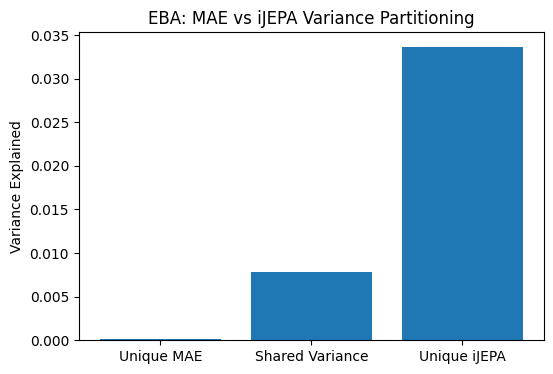

In [22]:
import matplotlib.pyplot as plt
import numpy as np

vals = {}

for _, row in results.iterrows():
    vals[row["Description"]] = np.mean(np.array(row["Values"]))

plot_names = [
    "Unique MAE",
    "Shared Variance",
    "Unique iJEPA"
]

plot_values = [vals[n] for n in plot_names]

plt.figure(figsize=(6,4))
plt.bar(plot_names, plot_values)
plt.ylabel("Variance Explained")
plt.title("EBA: MAE vs iJEPA Variance Partitioning")
plt.show()

# Unique Variance Partitioning for all ROIs

In [23]:
import os
import numpy as np
import pandas as pd
from scipy import stats
from net2brain.evaluations.variance_partitioning_analysis import VPA

#brain_path = os.path.join(paths_NSD_shared["root"], "brain_data")  
brain_path = os.path.join(paths_NSD_shared["root"], "combined_roi_rdms")  # combined lh and rh 

all_results = []

for roi in best_mae.index:

    print(f"Processing {roi}...")

    # --------------------------
    # Best layer for each model
    # --------------------------
    mae_row = best_mae.loc[roi]
    jepa_row = best_jepa.loc[roi]
    dino_row = best_dino.loc[roi]
    ibot_row = best_ibot.loc[roi]

    mae_layer = mae_row["Layer"].split(") ", 1)[1]
    jepa_layer = jepa_row["Layer"].split(") ", 1)[1]
    dino_layer = dino_row["Layer"].split(") ", 1)[1]
    ibot_layer = ibot_row["Layer"].split(") ", 1)[1]
    
    
    mae_rdm = os.path.join(
        r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\MAE_RDM_nsd",
        mae_layer
    )

    jepa_rdm = os.path.join(
        r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\jepa_RDM_nsd_all_layers",
        jepa_layer
    )

    dino_rdm = os.path.join(
        r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\\dino_RDM_nsd",
        dino_layer
    )
    ibot_rdm = os.path.join(
        r"C:\Users\louai\Net2Brain\notebooks\0_Model RDMS\\ibot_RDM_nsd",
        ibot_layer
    )

    # --------------------------
    # Brain RDM
    # --------------------------
    roi_filename = roi.split(") ", 1)[1]

    brain_file = os.path.join(
        brain_rdms,
        roi_filename + ".npz"
    )

    x = np.load(brain_file, allow_pickle=True)["rdm"]

    # --------------------------
    # Prepare dependent variable
    # --------------------------
    vpa = VPA(
        dependent_variable=[brain_file],
        independent_variables=[   # change these to the 2 models u want to compare
            ibot_rdm,   
            dino_rdm
        ],
        variable_names=[      # change the names too
            "IBOT",  # order matters. later becomes unique_model1
            "DINO"                   # Later becomes unique_model2
        ]
    )

    
    # Net2Brain workaround

    vpa.independent_1 = [vpa.independent_1]
    vpa.independent_2 = [vpa.independent_2]


    vpa.average_models = False

    dep_var = np.array([
        vpa.get_uppertriangular(subject)
        for subject in x
    ])

    dep_var = dep_var[:, None, :]

    # --------------------------
    # Variance Partitioning
    # --------------------------
    tmp1 = vpa.load_rdms(vpa.independent_1)
    tmp2 = vpa.load_rdms(vpa.independent_2)
    
    
    vp = vpa.VPA_function(
        dep_var,
        num_subjects=dep_var.shape[0],
        eeg_time=dep_var.shape[1]
    )

    unique_first_values = np.array(
        vp.loc[vp["Variable"] == "y1", "Values"].iloc[0]
    ).flatten()
    
    shared_values = np.array(
        vp.loc[vp["Variable"] == "y12", "Values"].iloc[0]
    ).flatten()
    
    unique_second_values = np.array(
        vp.loc[vp["Variable"] == "y2", "Values"].iloc[0]
    ).flatten()
    
    # Means
    unique_model1 = unique_first_values.mean()
    shared = shared_values.mean()
    unique_model2 = unique_second_values.mean()
    
    # Standard deviations
    unique_first_std = unique_first_values.std(ddof=1)
    shared_std = shared_values.std(ddof=1)
    unique_second_std = unique_second_values.std(ddof=1)

    # --------------------------
    # Paired t-test
    # --------------------------
    mae_arr = np.fromstring(
        mae_row["R2_array"].strip("[]"),
        sep=" "
    )

    jepa_arr = np.fromstring(
        jepa_row["R2_array"].strip("[]"),
        sep=" "
    )

    dino_arr = np.fromstring(
        dino_row["R2_array"].strip("[]"),
        sep=" "
    )
    ibot_arr = np.fromstring(
        ibot_row["R2_array"].strip("[]"),
        sep=" "
    )
    t_stat, p_value = stats.ttest_rel(dino_arr, mae_arr)  # change var names here

    # --------------------------
    # Save everything
    # --------------------------
    
    all_results.append({
        "ROI": roi,
        "Best_IBOT_Layer": ibot_layer, #change desplay names and var names here
        "Best_MAE_Layer": mae_layer,  #change desplay names and var names here
        "IBOT_R2": ibot_arr.mean(), #change desplay names and var names here
        "MAE_R2": mae_arr.mean(), #change desplay names and var names here
        "t": t_stat,
        "p": p_value,
    
        "Unique_IBOT": unique_model1, #change desplay names here
        "Unique_IBOT_STD": unique_first_std, #change desplay names here
    
        "Shared": shared,
        "Shared_STD": shared_std,
    
        "Unique_MAE": unique_model2, #change desplay names here
        "Unique_MAE_STD": unique_second_std #change desplay names here
    })

results_df = pd.DataFrame(all_results)

display(results_df)

#results_df.to_csv(r"C:\Users\louai\Net2Brain\notebooks\0_other results\uvp_ibot_dino_all_rois.csv", index=False) # change saved file name

Processing (0) EBA_combined_RDMs...
Processing (1) FFA-1_combined_RDMs...
Processing (10) V2d_combined_RDMs...
Processing (11) V2v_combined_RDMs...
Processing (12) V3d_combined_RDMs...
Processing (13) V3v_combined_RDMs...
Processing (14) VWFA-1_combined_RDMs...
Processing (2) hV4_combined_RDMs...
Processing (3) OFA_combined_RDMs...
Processing (4) OPA_combined_RDMs...
Processing (5) OWFA_combined_RDMs...
Processing (6) PPA_combined_RDMs...
Processing (7) RSC_combined_RDMs...
Processing (8) V1d_combined_RDMs...
Processing (9) V1v_combined_RDMs...


,ROI,Best_IBOT_Layer,Best_MAE_Layer,IBOT_R2,MAE_R2,t,p,Unique_IBOT,Unique_IBOT_STD,Shared,Shared_STD,Unique_MAE,Unique_MAE_STD
0,(0) EBA_combined_RDMs,RDM_layer_8.npz,RDM_layer_15.npz,0.028683,0.009439,8.402107,0.000067,0.000123,0.000126,0.030909,0.009740,0.003273,0.001153
1,(1) FFA-1_combined_RDMs,RDM_layer_9.npz,RDM_layer_15.npz,0.020357,0.006531,7.726797,0.000114,0.000259,0.000243,0.021705,0.008312,0.002206,0.000845
2,(10) V2d_combined_RDMs,RDM_layer_6.npz,RDM_layer_14.npz,0.004295,0.002816,4.293531,0.003595,0.000053,0.000052,0.004965,0.002596,0.000849,0.000522
3,(11) V2v_combined_RDMs,RDM_layer_6.npz,RDM_layer_15.npz,0.009080,0.008815,5.391892,0.001017,0.000730,0.000324,0.009931,0.003683,0.003520,0.001031
4,(12) V3d_combined_RDMs,RDM_layer_7.npz,RDM_layer_15.npz,0.004472,0.002606,3.537892,0.009497,0.000047,0.000063,0.005172,0.003446,0.000986,0.000961
5,(13) V3v_combined_RDMs,RDM_layer_9.npz,RDM_layer_15.npz,0.006279,0.004934,6.761899,0.000262,0.000047,0.000055,0.007426,0.002597,0.001734,0.000775
6,(14) VWFA-1_combined_RDMs,RDM_layer_8.npz,RDM_layer_14.npz,0.024590,0.008078,4.566788,0.002584,0.000199,0.000199,0.025700,0.015430,0.002417,0.001197
7,(2) hV4_combined_RDMs,RDM_layer_8.npz,RDM_layer_15.npz,0.008314,0.005352,6.092554,0.000495,0.000225,0.000093,0.009110,0.004214,0.002777,0.001073
8,(3) OFA_combined_RDMs,RDM_layer_8.npz,RDM_layer_15.npz,0.016382,0.005894,4.005252,0.005155,0.000040,0.000056,0.017750,0.011915,0.002240,0.001596
9,(4) OPA_combined_RDMs,RDM_layer_9.npz,RDM_layer_15.npz,0.033806,0.014300,6.941852,0.000223,0.000078,0.000109,0.036313,0.014560,0.007949,0.003827


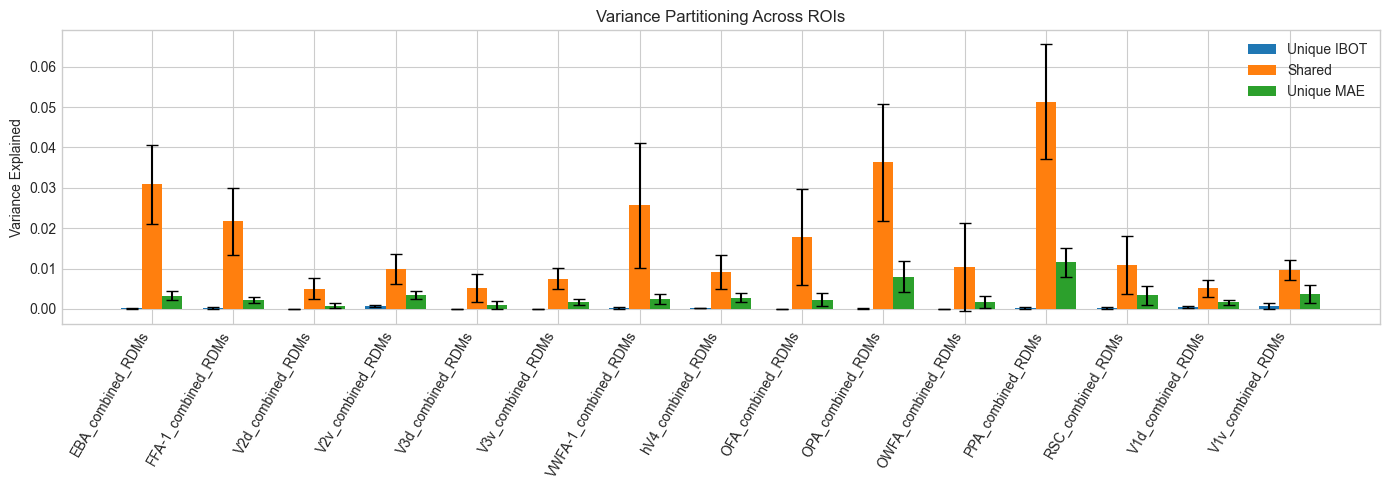

In [24]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = results_df.copy()

# remove "(0) " etc. from ROI names
plot_df["ROI"] = [ roi.split(") ", 1)[1] for roi in plot_df["ROI"] ]

x = np.arange(len(plot_df))
width = 0.25

plt.figure(figsize=(14,5))

plt.bar(
    x - width,
    plot_df["Unique_IBOT"], #here
    width,
    yerr=plot_df["Unique_IBOT_STD"], #here
    capsize=4,
    label="Unique IBOT" #here
)

plt.bar(
    x,
    plot_df["Shared"],
    width,
    yerr=plot_df["Shared_STD"],
    capsize=4,
    label="Shared"
)

plt.bar(
    x + width,
    plot_df["Unique_MAE"], #here
    width,
    yerr=plot_df["Unique_MAE_STD"], #here
    capsize=4,
    label="Unique MAE" #here
)

plt.xticks(x, plot_df["ROI"], rotation=60, ha="right")
plt.ylabel("Variance Explained")
plt.title("Variance Partitioning Across ROIs")
plt.legend()

plt.tight_layout()
plt.show()

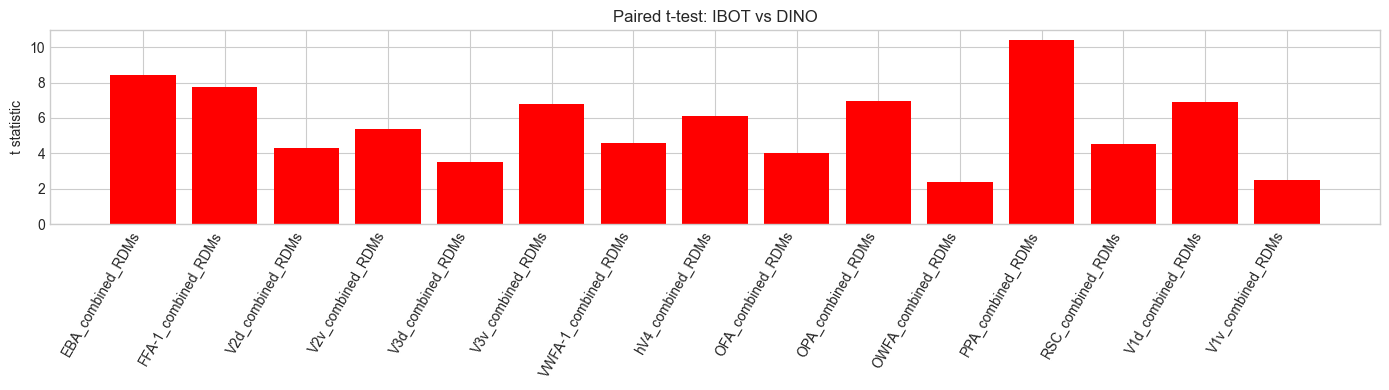

In [57]:
plt.figure(figsize=(14,4))

colors = ["red" if p < 0.05 else "gray" for p in results_df["p"]]

plt.bar(plot_df["ROI"], results_df["t"], color=colors)

plt.xticks(rotation=60, ha="right")
plt.ylabel("t statistic")
plt.title("Paired t-test: IBOT vs DINO") # change desplay names

plt.tight_layout()
plt.show()